# D — Fluid plasma models of comets

**Tutorial D1 · Cometary Plasma Modeling series**

Fluid codes are the first of the three model families listed by Goetz et al. (2022, *Space Sci. Rev.* 218:65, Sect. 3.3 and Table 5). Here **every plasma species is a fluid**: it is described only by its moments (density, bulk velocity, pressure). There are no individual particle orbits. Fluid codes work well when the gyroradii of the important ions are **small** compared with the size of the interaction region. That is the "strongly active" regime of Goetz et al. (Q ≳ 5×10²⁷ s⁻¹), comets like 1P/Halley.

This notebook builds two fluid models from scratch, from simplest to most complex:

| Part | Model | What it teaches | Benchmark |
|---|---|---|---|
| 1 | Steady, spherically symmetric **ion continuity** in the inner coma | Sources (photo-/electron-impact ionisation) vs. transport vs. dissociative recombination | Analytic solutions of Galand et al. (2016) and Beth et al. (2019), as quoted in Goetz et al. (2022), Eqs. 9–12 |
| 2 | 1-D, time-dependent, **mass-loaded MHD** along the Sun–comet line | The single-fluid MHD-with-source-terms method behind BATS-R-US (Gombosi et al. 1996) | Exact steady mass-loaded flow (Biermann et al. 1967 generalised to MHD) and the critical mass-loading limit |

Part 3 explains how production codes go beyond this: multi-fluid MHD, ion–neutral chemistry, and 3-D adaptive grids.

> **Learning goals.** By the end you should be able to (i) write the source terms that couple a neutral coma to a plasma fluid, (ii) implement a conservative finite-volume MHD solver with those sources, and (iii) say when a fluid description of a cometary plasma stops being trustworthy.

## 0. Where fluid models sit in the comet literature

Representative fluid codes applied to comets. The physics columns are what the papers describe; check each paper for details:

| Code / approach | Fluid treatment | Comet applications |
|---|---|---|
| **BATS-R-US** (Univ. Michigan; Powell et al. 1999; Tóth et al. 2012) | Single-fluid ideal MHD with mass-loading, charge-exchange and recombination source terms; 3-D block-adaptive grid | Gombosi et al. (1996); Hansen et al. (2007) predictions for 67P; Rubin et al. (2014) |
| **Multi-fluid BATS-R-US** | Separate continuity/momentum/energy equations per ion fluid (e.g. solar-wind H⁺ and cometary H₂O⁺), plus a neutral fluid and separate electron pressure | Rubin et al. (2014); Huang et al. (2016) four-fluid model of 67P near perihelion |
| **1-D / analytic ionosphere models** | Steady ion continuity with ionisation, transport and recombination | Galand et al. (2016); Heritier et al. (2017); Beth et al. (2019); Vigren et al. (2015) |
| **Biermann-type 1-D mass-loaded flow** | Conservation laws along a streamline with mass addition | Biermann, Brosowski & Schmidt (1967), the classic estimate of when a cometary shock must form |

The common skeleton is the set of moment equations for species *s*, with source terms for ionisation and other processes:

$$
\frac{\partial \rho_s}{\partial t} + \nabla\cdot(\rho_s \mathbf u_s) = \dot\rho_s^{\,\rm ion} - \dot\rho_s^{\,\rm loss},
$$
$$
\frac{\partial (\rho_s \mathbf u_s)}{\partial t} + \nabla\cdot(\rho_s \mathbf u_s\mathbf u_s + p_s\mathsf I) = n_s q_s(\mathbf E + \mathbf u_s\times\mathbf B) + \dot\rho_s^{\,\rm ion}\mathbf u_n - \rho_s\nu_{sn}(\mathbf u_s-\mathbf u_n) + \dots
$$

In **single-fluid MHD** the species are summed. Assuming quasi-neutrality and ideal Ohm's law, $\mathbf E = -\mathbf u\times\mathbf B$, the Lorentz force becomes $\mathbf J\times\mathbf B$ and Faraday's law closes the system.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# Physical constants (SI)
mp, kB, mu0, amu = 1.67262e-27, 1.380649e-23, 4e-7*np.pi, 1.66054e-27

## Part 1 — The simplest fluid model: ion continuity in the inner coma

### 1a. Neutral background: the Haser model
Every cometary plasma model needs a neutral coma as its source. The standard choice is the spherically symmetric Haser (1957) model, Goetz et al. (2022) Eq. 1:

$$ n_n(r) = \frac{Q}{4\pi U_n r^2}\, e^{-(r-r_c)\,k_p/U_n}. $$

Within a few thousand km of the nucleus the exponential is ≈ 1, because $U_n/k_p \sim 10^6$ km.

### 1b. Steady ion continuity
For a single ion fluid moving radially at speed $u_i$, with ionisation frequency $\nu$ and dissociative recombination (DR) coefficient $\alpha$ (Goetz et al. 2022, Eq. 8):

$$ \frac{1}{r^2}\frac{d}{dr}\left(n_i u_i r^2\right) = \nu\, n_n(r) - \alpha\, n_i^2 .$$

This is a 1-D ODE. Without DR and with $u_i = U_n$ it has the analytic solution of Galand et al. (2016) (Goetz Eq. 10):
$$ n_i(r) = \frac{\nu\,Q\,(r-r_c)}{4\pi U_n^2 r^2},$$
which peaks at $r = 2r_c$. With DR and $u_i = U_n$, Beth et al. (2019) give the closed form (Goetz Eq. 12):
$$ n_i(r) = (\gamma-1)\frac{U_n}{2\alpha r}\,\frac{R^\gamma-1}{R^\gamma + \frac{\gamma-1}{\gamma+1}},\qquad \gamma=\sqrt{1+Q/Q_0},\quad Q_0=\frac{\pi U_n^3}{\nu\alpha},\quad R=r/r_c. $$

We integrate the ODE numerically and check it against both formulas. This is the "fluid code" in its most stripped-down form.

Q=1e+26: max rel. error vs Galand+2016 = 1.7e-14, vs Beth+2019 = 1.4e-10
Q=1e+27: max rel. error vs Galand+2016 = 2.2e-14, vs Beth+2019 = 1.7e-10
Q=1e+28: max rel. error vs Galand+2016 = 1.6e-14, vs Beth+2019 = 6.6e-11
Q=1e+29: max rel. error vs Galand+2016 = 1.0e-14, vs Beth+2019 = 2.0e-10


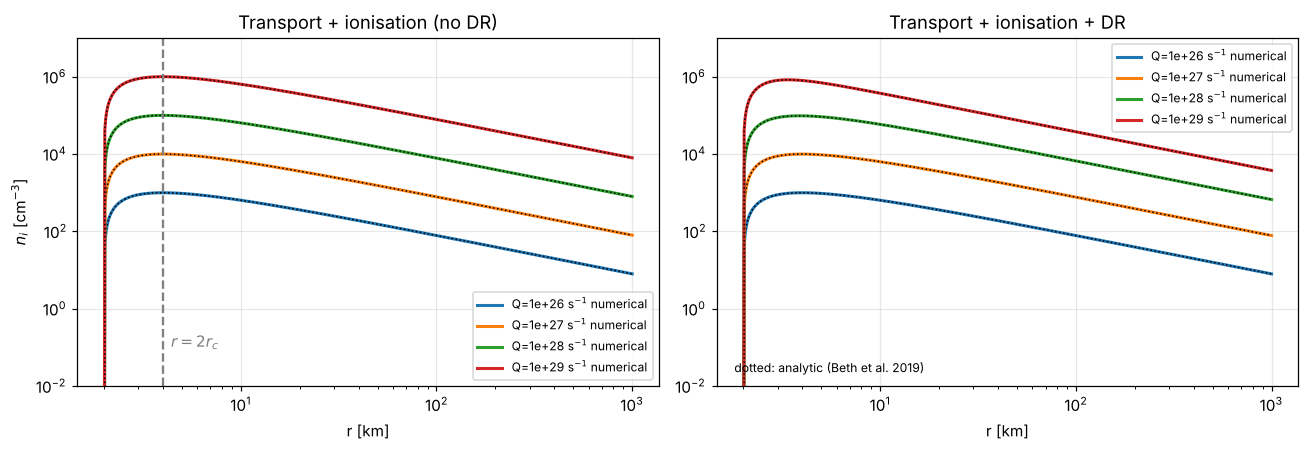

Peak of n_i (no DR) at r = 2.004 r_c  (theory: 2 r_c)


In [2]:
# 67P-like inner-coma parameters
rc   = 2.0e3        # nucleus radius [m]
Un   = 1.0e3        # neutral (= ion) radial speed [m/s]
nu   = 1.0e-6       # total ionisation frequency (PI + EI) [1/s]
alpha= 3.0e-13      # DR coefficient [m^3/s] (~3e-7 cm^3/s, cold electrons)

def ion_continuity(Q, with_DR=True, r_max_factor=500):
    """Integrate d(n u r^2)/dr = r^2 [nu n_n - alpha n^2] outward from the surface (n=0 at r=rc)."""
    def rhs(r, y):
        n = y[0] / r**2
        src = nu * Q / (4*np.pi*Un*r**2)
        loss = alpha*n**2 if with_DR else 0.0
        return [(src - loss) * r**2 / Un]
    r = np.geomspace(rc, r_max_factor*rc, 600)
    sol = solve_ivp(rhs, [rc, r[-1]], [0.0], t_eval=r, rtol=1e-10, atol=1e-6, method='LSODA')
    return r, sol.y[0]/r**2

def galand2016(r, Q):
    return nu*Q*(r-rc)/(4*np.pi*Un**2*r**2)

def beth2019(r, Q):
    Q0 = np.pi*Un**3/(nu*alpha); g = np.sqrt(1+Q/Q0); R = r/rc
    return (g-1)*Un/(2*alpha*r) * (R**g-1)/(R**g+(g-1)/(g+1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for Q, c in [(1e26,'C0'), (1e27,'C1'), (1e28,'C2'), (1e29,'C3')]:
    r, n0 = ion_continuity(Q, with_DR=False)
    r, n1 = ion_continuity(Q, with_DR=True)
    ax[0].loglog(r/1e3, n0/1e6, c, lw=2, label=f'Q={Q:.0e} s$^{{-1}}$ numerical')
    ax[0].loglog(r/1e3, galand2016(r,Q)/1e6, 'k:', lw=1)
    ax[1].loglog(r/1e3, n1/1e6, c, lw=2, label=f'Q={Q:.0e} s$^{{-1}}$ numerical')
    ax[1].loglog(r/1e3, beth2019(r,Q)/1e6, 'k:', lw=1)
    err0 = np.max(np.abs(n0[1:]/galand2016(r[1:],Q)-1)); err1 = np.max(np.abs(n1[1:]/beth2019(r[1:],Q)-1))
    print(f'Q={Q:.0e}: max rel. error vs Galand+2016 = {err0:.1e}, vs Beth+2019 = {err1:.1e}')
ax[0].axvline(2*rc/1e3, color='gray', ls='--'); ax[0].text(2*rc/1e3*1.1, 1e-1, '$r=2r_c$', color='gray')
ax[0].set(title='Transport + ionisation (no DR)', xlabel='r [km]', ylabel='$n_i$ [cm$^{-3}$]', ylim=(1e-2, 1e7))
ax[1].set(title='Transport + ionisation + DR', xlabel='r [km]', ylim=(1e-2, 1e7))
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
ax[1].text(0.03, 0.04, 'dotted: analytic (Beth et al. 2019)', transform=ax[1].transAxes, fontsize=8)
plt.tight_layout(); plt.show()

r, n = ion_continuity(1e27, with_DR=False)
print(f'Peak of n_i (no DR) at r = {r[np.argmax(n)]/rc:.3f} r_c  (theory: 2 r_c)')

**What to notice**

* The numerical and analytic curves agree to near machine precision. That confirms the ODE is the same equation the analytic papers solve.
* Without DR, $n_i \propto Q$ and falls as $1/r$ far out. That is the $1/r$ trend Rosetta saw near 67P (Edberg et al. 2015).
* With DR (right panel), compare Q = 10²⁸ and 10²⁹ s⁻¹ with the left panel. Here $Q_0 \approx 10^{28}$ s⁻¹, so recombination caps the density and it saturates as Q rises ($n_i \propto \sqrt Q$ when $Q \gg Q_0$). Recombination matters only for very active comets or very cold electrons.

**Limitations that motivate everything else in this series.** The ions here move with the neutrals. Real ions at 67P were accelerated by an ambipolar electric field (see tutorial F) and by the solar-wind convective field (see tutorial E). A pure continuity model cannot capture either effect.

## Part 2 — Mass-loaded MHD along the Sun–comet line

This is the core idea of global MHD comet models such as BATS-R-US (Gombosi et al. 1996). The solar wind is one MHD fluid. Newly ionised cometary molecules are added to it as **source terms**:

$$
\frac{\partial}{\partial t}\begin{pmatrix}\rho\\ \rho u\\ B\\ \mathcal E\end{pmatrix}
+\frac{\partial}{\partial x}\begin{pmatrix}\rho u\\ \rho u^2 + p + B^2/2\mu_0\\ uB\\ (\mathcal E + p + B^2/2\mu_0)\,u\end{pmatrix}
=\begin{pmatrix}\dot\rho\\ \dot\rho\, u_n\\ 0\\ \tfrac12\dot\rho\, u_n^2\end{pmatrix},
\qquad \dot\rho = m_i\,\nu\, n_n(x).
$$

We use 1-D geometry: flow along $x$ (the Sun–comet line) and a transverse field $B=B_y$ perpendicular to the flow. That is the "stagnation-line" geometry. Because new ions are born essentially at rest ($u_n \approx 1$ km/s ≪ 400 km/s), mass is added but almost no momentum or energy. Total momentum is conserved while mass grows, so the bulk flow must slow down. The kinetic energy given up is converted into thermal energy. This is the fluid version of **pickup-ion heating**.

### 2a. The exact steady solution (Biermann et al. 1967, with B)
In steady state, $\rho u = F(x)$ (the mass flux grows as mass is added), while the momentum flux $\Pi$, the energy flux $\mathcal{F}_E$ and the electric field $uB$ stay constant. Eliminating $p$ and $B$ gives one algebraic equation for $u$ at each $x$:

$$ \tfrac12 F u^2 + \frac{\gamma}{\gamma-1}\Big(\Pi - F u - \frac{(u_0B_0)^2}{2\mu_0 u^2}\Big)u + \frac{(u_0B_0)^2}{\mu_0 u} = \mathcal F_E. $$

The supersonic branch exists only while $F$ is below a **critical value**. For a cold, unmagnetised flow that limit is $F_{\rm crit}/F_0 = \gamma^2/(\gamma^2-1) = 25/16$ (Biermann et al. 1967). Beyond it, no smooth steady supersonic solution exists. The flow has to pass through a **shock**, which is the cometary bow shock.

In [3]:
# --- solar wind at ~1.3 AU and a water-dominated coma ---
gam = 5/3
n_sw, u_sw, B_sw, T_sw = 5e6, -4.0e5, 5e-9, 1e5      # m^-3, m/s (toward -x), T, K
rho0 = n_sw*mp; p0 = 2*n_sw*kB*T_sw                   # proton + electron pressure
mi, nu_i, Un = 18*amu, 1e-6, 1e3                       # water ions, ionisation rate, neutral speed

# --- 1-D finite-volume grid on the sunward side of the nucleus ---
xmin, xmax, N = 2.0e6, 6.0e7, 1200                     # 2,000 km ... 60,000 km
xe = np.linspace(xmin, xmax, N+1); x = 0.5*(xe[1:]+xe[:-1]); dx = xe[1]-xe[0]

def massload(x, Q):
    """Mass-loading rate rho_dot = m_i * nu * n_n(x)  [kg m^-3 s^-1]  (Haser, no decay)."""
    return mi*nu_i*Q/(4*np.pi*Un*x**2)

def cons(rho, u, B, p):
    return np.array([rho, rho*u, B, p/(gam-1) + 0.5*rho*u**2 + B**2/(2*mu0)])

def prim(U):
    rho, m, B, E = U; u = m/rho
    return rho, u, B, (gam-1)*(E - 0.5*rho*u**2 - B**2/(2*mu0))

def flux(U):
    rho, u, B, p = prim(U); pt = p + B**2/(2*mu0)
    return np.array([rho*u, rho*u**2 + pt, B*u, (U[3] + pt)*u])

def fastspeed(U):
    rho, u, B, p = prim(U)
    return np.abs(u) + np.sqrt((gam*np.maximum(p, 1e-30) + B**2/mu0)/rho)

### 2b. The numerical scheme
We use a standard second-order **MUSCL–Rusanov** finite-volume scheme (e.g. Toro 2009). It is simpler than the Roe/HLLD solvers in BATS-R-US, but it has the same structure:

1. Reconstruct primitive variables at cell faces with a minmod-limited linear slope.
2. Compute the face flux with the Rusanov (local Lax–Friedrichs) formula, $\hat F = \tfrac12(F_L+F_R) - \tfrac12 a_{\max}(U_R-U_L)$, where $a_{\max} = |u| + c_{\rm fast}$.
3. Update conserved variables, then add the mass-loading source (**operator splitting**).
4. Boundaries: fixed solar-wind inflow on the sunward side, zero-gradient outflow toward the nucleus.

In [4]:
def run_mhd(Q, t_end, cfl=0.4, snapshots=()):
    U = cons(rho0*np.ones(N), u_sw*np.ones(N), B_sw*np.ones(N), p0*np.ones(N))
    Uin = cons(rho0, u_sw, B_sw, p0); S = massload(x, Q)
    t, snaps, todo = 0.0, [], sorted(snapshots)
    while t < t_end:
        Ug = np.concatenate([U[:, :1], U, Uin[:, None]], axis=1)          # ghost cells
        P = np.array(prim(Ug))
        dl, dr = P[:, 1:-1]-P[:, :-2], P[:, 2:]-P[:, 1:-1]
        slope = np.where(dl*dr > 0, np.sign(dl)*np.minimum(abs(dl), abs(dr)), 0.0)  # minmod
        PL = np.concatenate([P[:, :1], P[:, 1:-1]+0.5*slope], axis=1)       # left state at each face
        PR = np.concatenate([P[:, 1:-1]-0.5*slope, P[:, -1:]], axis=1)      # right state at each face
        UL, UR = cons(*PL), cons(*PR)
        a = np.maximum(fastspeed(UL), fastspeed(UR))
        F = 0.5*(flux(UL)+flux(UR)) - 0.5*a*(UR-UL)                       # Rusanov flux
        dt = min(cfl*dx/np.max(fastspeed(U)), t_end - t)
        U = U - dt/dx*(F[:, 1:] - F[:, :-1])
        U[0] += dt*S        # mass source. Momentum (S*u_n) and energy (S*u_n^2/2) sources are
                            # negligible because u_n ~ 1 km/s << |u_sw|, so they are omitted.
        t += dt
        while todo and t >= todo[0]:
            snaps.append((todo.pop(0), prim(U)));
    return prim(U), snaps

def steady_analytic(Q):
    """Exact steady supersonic mass-loaded MHD solution u(x); NaN where no supersonic root exists."""
    F0 = rho0*u_sw; Pi = rho0*u_sw**2 + p0 + B_sw**2/(2*mu0)
    FE = (0.5*rho0*u_sw**2 + gam/(gam-1)*p0)*u_sw + u_sw*B_sw**2/mu0
    E0 = u_sw*B_sw
    F = F0 - mi*nu_i*Q/(4*np.pi*Un)*(1/x - 1/xmax)              # flux grows (more negative) toward nucleus
    out = np.full(N, np.nan); uu = np.linspace(u_sw*1.0001, u_sw*0.01, 4000)
    for k, Fk in enumerate(F):
        res = lambda u: 0.5*Fk*u**2 + gam/(gam-1)*(Pi - Fk*u - E0**2/(2*mu0*u**2))*u + E0**2/(mu0*u) - FE
        r = res(uu); idx = np.where(np.sign(r[:-1]) != np.sign(r[1:]))[0]
        if len(idx): out[k] = brentq(res, uu[idx[0]], uu[idx[0]+1])   # first root = supersonic branch
    return out

# Critical production rate: smallest Q for which the steady solution fails before reaching x_min
def has_solution(Q): return np.isfinite(steady_analytic(Q)[0])
Qc = brentq(lambda lq: 0.5 - has_solution(10**lq), 25, 29, xtol=1e-3)
Q_crit = 10**Qc
print(f'Critical production rate for a shock-free flow down to {xmin/1e3:.0f} km: Q_crit = {Q_crit:.2e} s^-1')

F_ratio_hydro = gam**2/(gam**2-1)
print(f'Biermann (cold, B=0) limit F_crit/F0 = {F_ratio_hydro:.4f}')

Critical production rate for a shock-free flow down to 2000 km: Q_crit = 1.39e+27 s^-1
Biermann (cold, B=0) limit F_crit/F0 = 1.5625


### 2c. Sub-critical case: does the code reproduce the exact solution?
We run at $Q = 0.5\,Q_{\rm crit}$ for six solar-wind crossing times, long enough to reach steady state, and compare with the exact curve.

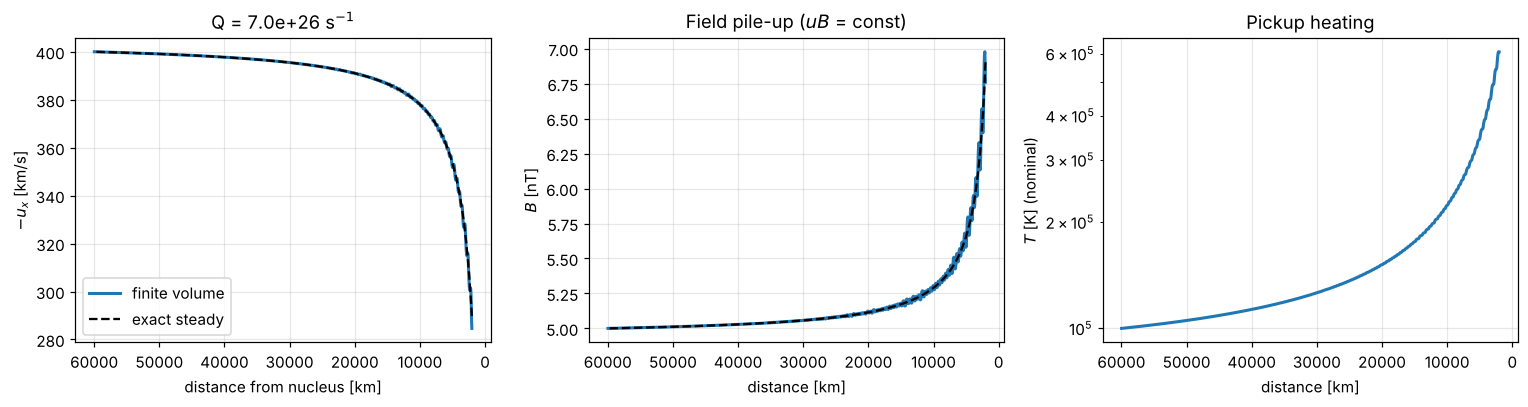

max |u_num/u_exact - 1| = 1.77%


In [5]:
Q_sub = 0.5*Q_crit
t_cross = (xmax-xmin)/abs(u_sw)
(rho, u, B, p), _ = run_mhd(Q_sub, 6*t_cross)
ua = steady_analytic(Q_sub)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(x/1e3, -u/1e3, lw=2, label='finite volume'); ax[0].plot(x/1e3, -ua/1e3, 'k--', label='exact steady')
ax[0].set(xlabel='distance from nucleus [km]', ylabel='$-u_x$ [km/s]', title=f'Q = {Q_sub:.1e} s$^{{-1}}$')
ax[0].legend()
ax[1].plot(x/1e3, B/1e-9, lw=2); ax[1].plot(x/1e3, B_sw*u_sw/ua/1e-9, 'k--')
ax[1].set(xlabel='distance [km]', ylabel='$B$ [nT]', title='Field pile-up ($uB$ = const)')
T = p/(2*(rho/mp)*kB)  # rough temperature using proton-mass number density
ax[2].semilogy(x/1e3, T, lw=2); ax[2].set(xlabel='distance [km]', ylabel='$T$ [K] (nominal)', title='Pickup heating')
for a in ax: a.invert_xaxis()
plt.tight_layout(); plt.show()
print(f'max |u_num/u_exact - 1| = {np.nanmax(np.abs(u/ua-1)):.2%}')

The solver matches the exact solution to within about 2 %. The largest residual sits in the last few cells before the outflow boundary, where numerical diffusion is strongest. Moving toward the nucleus, the solar wind decelerates, the magnetic field piles up, and the plasma heats: the first steps of the comet–solar-wind interaction.

### 2d. Super-critical case: a shock forms
At $Q = 1.5\,Q_{\rm crit}$ the flow cannot absorb the added mass smoothly. Watch what the time-dependent solver does.

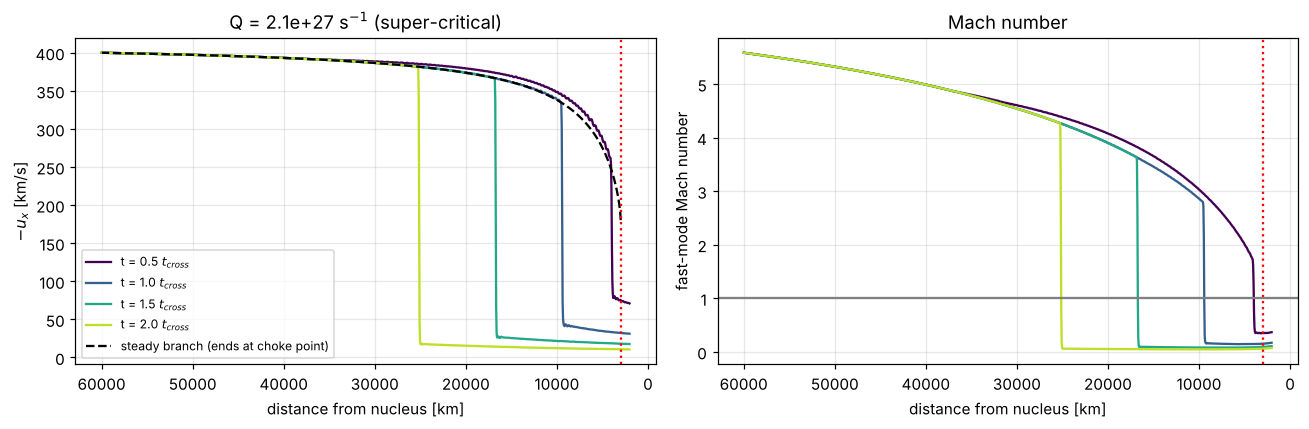

Choke point of the steady supersonic branch: 2991 km from the nucleus


In [6]:
Q_sup = 1.5*Q_crit
times = [0.5*t_cross, 1.0*t_cross, 1.5*t_cross, 2.0*t_cross]
_, snaps = run_mhd(Q_sup, times[-1]+1, snapshots=times)
ua_sup = steady_analytic(Q_sup)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (t, (rho, u, B, p)), c in zip(snaps, plt.cm.viridis(np.linspace(0, 0.9, len(snaps)))):
    cf = np.sqrt((gam*p + B**2/mu0)/rho)
    ax[0].plot(x/1e3, -u/1e3, color=c, label=f't = {t/t_cross:.1f} $t_{{cross}}$')
    ax[1].plot(x/1e3, np.abs(u)/cf, color=c)
ax[0].plot(x/1e3, -ua_sup/1e3, 'k--', label='steady branch (ends at choke point)')
xc = x[np.where(np.isfinite(ua_sup))[0][0]]
for a in ax: a.axvline(xc/1e3, color='r', ls=':'); a.invert_xaxis(); a.set_xlabel('distance from nucleus [km]')
ax[0].set(ylabel='$-u_x$ [km/s]', title=f'Q = {Q_sup:.1e} s$^{{-1}}$ (super-critical)'); ax[0].legend(fontsize=8)
ax[1].axhline(1, color='gray'); ax[1].set(ylabel='fast-mode Mach number', title='Mach number')
plt.tight_layout(); plt.show()
print(f'Choke point of the steady supersonic branch: {xc/1e3:.0f} km from the nucleus')

**Interpretation.**
* The steady supersonic branch ends at the choke point (red dotted line). Beyond it, the solver produces a jump to subsonic flow: a **shock**.
* In this strictly 1-D model the shock does not settle. It keeps moving upstream, because momentum and energy fluxes are conserved across a shock, so the subsonic flow behind it hits the same mass-loading limit. In 3-D the subsonic plasma **flows around** the coma, and the shock stands at a finite distance. Global MHD codes (Gombosi et al. 1996; Hansen et al. 2007; Rubin et al. 2014) therefore run in 3-D. The Biermann choke point is still the classic order-of-magnitude estimate of the bow-shock stand-off distance.
* The fluid picture assumes the pickup ions thermalise instantly. Their gyroradius is $r_g = m_i u_{sw}/(eB) \approx 15{,}000$ km here, comparable to the whole domain. At 67P-like activity that assumption fails. Goetz et al. (2022) call this the **kinetic regime**, and it motivates the hybrid codes in tutorial E.

In [7]:
rg = mi*abs(u_sw)/(1.602e-19*B_sw)
print(f'Water-ion pickup gyroradius in the undisturbed solar wind: {rg/1e3:,.0f} km')
print(f'Distance of choke point for Q = {Q_sup:.1e}: {xc/1e3:,.0f} km  ->  ratio r_g / x_choke = {rg/xc:.1f}')

Water-ion pickup gyroradius in the undisturbed solar wind: 14,926 km
Distance of choke point for Q = 2.1e+27: 2,991 km  ->  ratio r_g / x_choke = 5.0


## Part 3 — From this notebook to a production fluid code

| This tutorial | Production codes (e.g. BATS-R-US) |
|---|---|
| 1-D, uniform grid | 3-D, block-adaptive grid from ~10 m near the nucleus to 10⁶ km |
| Rusanov flux, minmod | Roe / HLLD / Linde fluxes; 8-wave or hyperbolic cleaning for ∇·B = 0 |
| Single fluid | Multi-fluid: separate H⁺ (solar wind), H₂O⁺ (cometary) and neutral fluids, plus separate electron pressure (Rubin et al. 2014; Huang et al. 2016) |
| Mass loading only | Photo-/electron-impact ionisation, charge exchange, ion–neutral friction, dissociative recombination, electron–neutral cooling |
| Spherical Haser coma | DSMC or empirical, 3-D, time-varying neutral comae driven by Rosetta data |

**When to trust a fluid model at a comet.** Fluid models are reliable for large-scale structure (bow shock, magnetic pile-up, diamagnetic cavity) when cometary-ion gyroradii are small compared with the interaction region. At weakly to moderately active comets (Q ≲ 10²⁷ s⁻¹), Rosetta found strongly non-gyrotropic ion behaviour: the solar wind was deflected and cometary ions were picked up sideways. Single-fluid MHD cannot reproduce this (Rubin et al. 2014; Goetz et al. 2022, Sect. 2.3.1).

### Exercises
1. Set `alpha` to a value typical of 10-eV electrons (≈10⁻¹⁴ m³ s⁻¹). Using Goetz et al. (2022) Sect. 2.2.4, explain why DR then becomes negligible at 67P.
2. In Part 2, set `B_sw = 0` and confirm numerically that the choke occurs at $F/F_0 = 25/16$.
3. Add an ion–neutral friction term $-\rho\,\nu_{in}(u-u_n)$ to the momentum equation and see how the choke point moves.
4. *(Advanced)* Extend the solver to two ion fluids (H⁺ and H₂O⁺), each with its own momentum equation, coupled through a common $\mathbf E = -\mathbf u_e\times\mathbf B$. This is the essence of multi-fluid MHD.

## References
* Biermann, L., Brosowski, B., & Schmidt, H. U. (1967). The interaction of the solar wind with a comet. *Solar Physics*, 1, 254–284.
* Edberg, N. J. T., et al. (2015). Spatial distribution of low-energy plasma around comet 67P/CG from Rosetta measurements. *GRL*, 42, 4263–4269.
* Galand, M., et al. (2016). Ionospheric plasma of comet 67P probed by Rosetta at 3 au from the Sun. *MNRAS*, 462, S331–S351.
* Goetz, C., et al. (2022). The plasma environment of comet 67P/Churyumov-Gerasimenko. *Space Sci. Rev.*, 218, 65. https://doi.org/10.1007/s11214-022-00931-1
* Gombosi, T. I., De Zeeuw, D. L., Häberli, R. M., & Powell, K. G. (1996). Three-dimensional multiscale MHD model of cometary plasma environments. *JGR*, 101(A7), 15233–15253.
* Hansen, K. C., et al. (2007). The plasma environment of comet 67P/Churyumov-Gerasimenko throughout the Rosetta main mission. *Space Sci. Rev.*, 128, 133–166.
* Haser, L. (1957). Distribution d'intensité dans la tête d'une comète. *Bull. Soc. R. Sci. Liège*, 43, 740–750.
* Huang, Z., et al. (2016). Four-fluid MHD simulations of the plasma and neutral gas environment of comet Churyumov-Gerasimenko near perihelion. *JGR Space Phys.*, 121, 4247–4268.
* Powell, K. G., et al. (1999). A solution-adaptive upwind scheme for ideal magnetohydrodynamics. *J. Comput. Phys.*, 154, 284–309.
* Rubin, M., et al. (2014). Plasma environment of a weak comet – Predictions for comet 67P/Churyumov-Gerasimenko from multifluid-MHD and hybrid models. *Icarus*, 242, 38–49.
* Tóth, G., et al. (2012). Adaptive numerical algorithms in space weather modeling. *J. Comput. Phys.*, 231, 870–903.
* Toro, E. F. (2009). *Riemann Solvers and Numerical Methods for Fluid Dynamics* (3rd ed.). Springer.
* Beth et al. (2019), Heritier et al. (2017), Vigren et al. (2015): see the reference list of Goetz et al. (2022) for full citations.